# K-Means Clustering on Iris Dataset

In [41]:
# Load Iris dataset
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import numpy as np
import pandas as pd


In [42]:
# Load the Iris dataset
iris = load_iris()
X = iris.data
y=iris.target

In [43]:
X, y

(array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
        [5

In [44]:
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

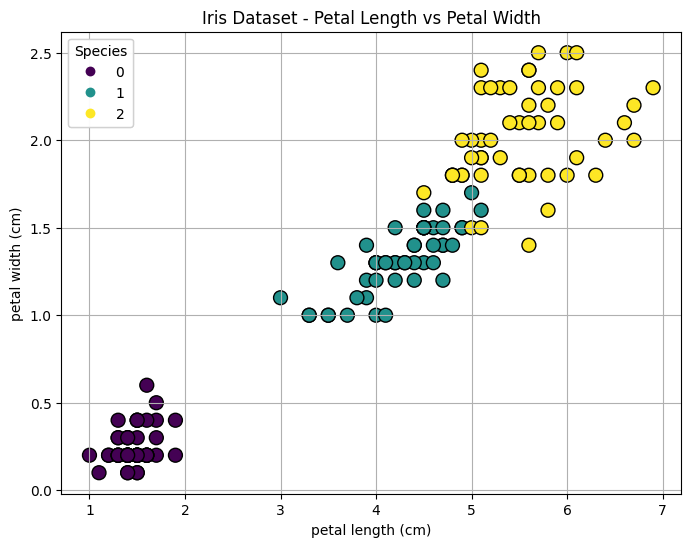

In [45]:

# Convert to a DataFrame for better visualization and labeling
iris_df = pd.DataFrame(X, columns=iris.feature_names)
iris_df['species'] = pd.Categorical.from_codes(y, iris.target_names)

# Plotting the data
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X[:, 2], X[:, 3], c=y, cmap='viridis', edgecolor='k', s=100)

# Adding labels
plt.xlabel(iris.feature_names[2])  # Petal length
plt.ylabel(iris.feature_names[3])  # Petal width
plt.title("Iris Dataset - Petal Length vs Petal Width")

# Adding legend for species
legend1 = plt.legend(*scatter.legend_elements(), title="Species")
plt.gca().add_artist(legend1)

# Display the plot
plt.grid(True)
plt.show()

In [46]:
iris_df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


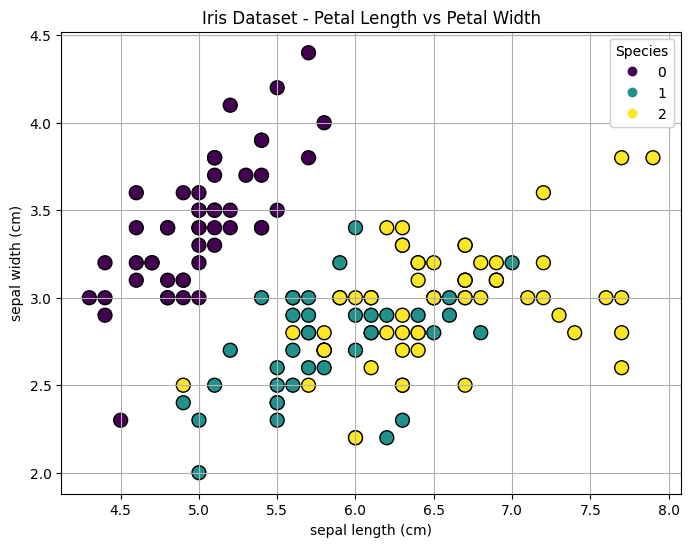

In [47]:

# Convert to a DataFrame for better visualization and labeling
iris_df = pd.DataFrame(X, columns=iris.feature_names)
iris_df['species'] = pd.Categorical.from_codes(y, iris.target_names)

# Plotting the data
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', edgecolor='k', s=100)

# Adding labels
plt.xlabel(iris.feature_names[0])  # Petal length
plt.ylabel(iris.feature_names[1])  # Petal width
plt.title("Iris Dataset - Petal Length vs Petal Width")

# Adding legend for species
legend1 = plt.legend(*scatter.legend_elements(), title="Species")
plt.gca().add_artist(legend1)

# Display the plot
plt.grid(True)
plt.show()

## Elbow Method

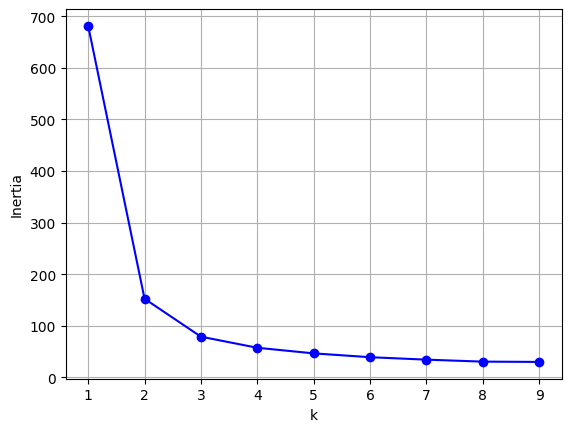

In [48]:
# Elbow
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X)
                for k in range(1, 10)]
inertias = [model.inertia_ for model in kmeans_per_k]

plt.plot(range(1, 10), inertias, 'bo-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.grid()
plt.show()

## Silhouette Analysis

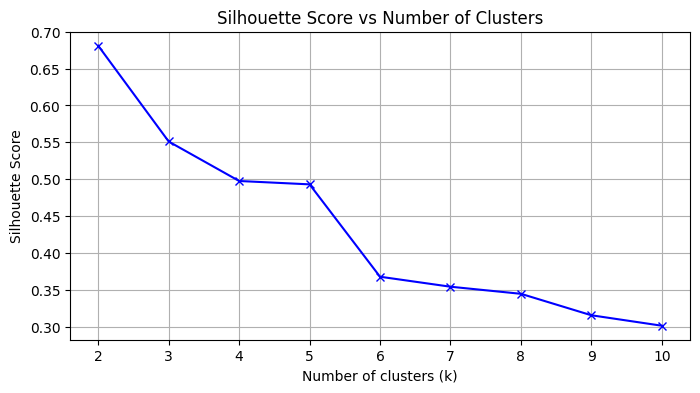

In [49]:

# Silhouette analysis for various values of k
from sklearn.metrics import silhouette_score

silhouette_scores = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    y_pred = kmeans.fit_predict(X)
    silhouette_scores.append(silhouette_score(X, y_pred))

# Plotting the silhouette scores
plt.figure(figsize=(8, 4))
plt.plot(range(2, 11), silhouette_scores, 'bx-')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs Number of Clusters')
plt.grid(True)
plt.show()


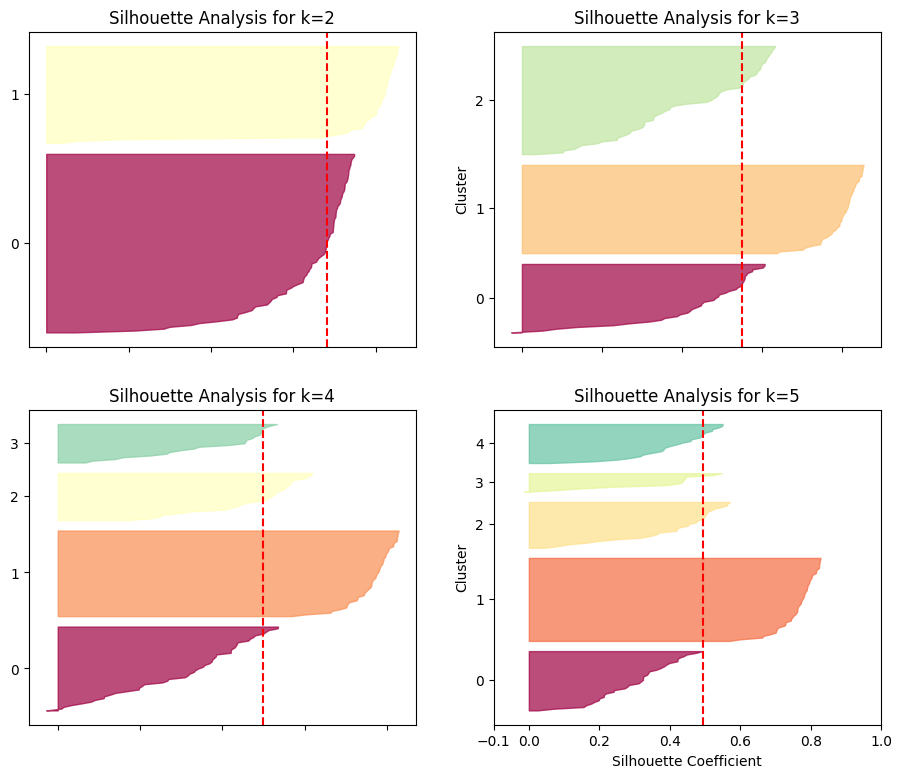

In [50]:
# Step 3: Silhouette Coefficient Visualization for Different Values of k
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter

plt.figure(figsize=(11, 9))  # Create a large figure for subplots

# Loop over values of k (2, 3, 4, 5)
for k in (2, 3, 4, 5):
    plt.subplot(2, 2, k - 1)  # Create a 2x2 grid of plots, one for each k

    # Get predicted labels for the corresponding k
    y_pred = kmeans_per_k[k - 1].labels_

    # Calculate silhouette coefficients for each point
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30  # Define padding between clusters for better visibility
    pos = padding
    ticks = []  # To store tick positions for cluster labels
    for i in range(k):
        # Get silhouette coefficients for cluster i and sort them
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        # Assign a color for each cluster
        color = plt.cm.Spectral(i / k)

        # Fill the silhouette coefficients as a shaded area
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding  # Update position for the next cluster

    # Setting up y-axis ticks and labels for clusters
    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))

    # Adding y-axis label for the first two plots
    if k in (3, 5):
        plt.ylabel("Cluster")

    # Adding x-axis labels for the last two plots
    if k in (5, 6):
        plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
        plt.xlabel("Silhouette Coefficient")
    else:
        plt.tick_params(labelbottom=False)

    # Plot a vertical line showing the average silhouette score for each k
    plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title(f"Silhouette Analysis for k={k}")

plt.show()  # Show the plots


In [51]:
# Choose two features for 2D plotting
X = X[:, [2, 3]]         # change indices if you want other features
kmeans = KMeans(n_clusters=3, random_state=42)
y_pred_k3 = kmeans.fit_predict(X)
# then plot exactly as above with X

In [52]:
def plot_clusters(X, y=None):
  plt.scatter(X[:, 0], X[:, 1], c=y, s=10)
  plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c='red', s=100, marker='X')

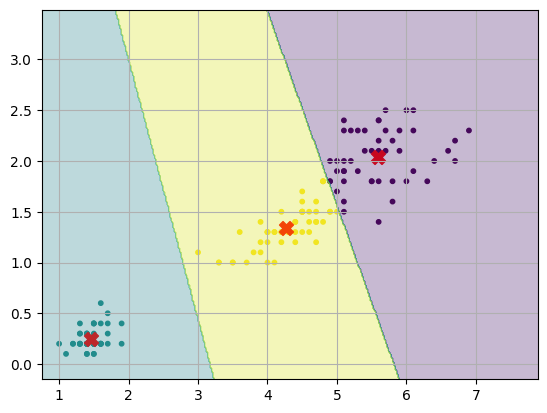

In [53]:
plot_clusters(X, y_pred_k3)
# Plot Voronoi tessellation (decision boundaries)
# Create a mesh grid
x_min, x_max = X[:, 0].min() - 0.25, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 0.25, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

# Predict cluster label for each point in the mesh grid
Z = kmeans.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot the decision boundaries by filling regions with cluster colors
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
plt.grid()
plt.show()